# OVM Assignment 1



### 1
Plot daily close prices


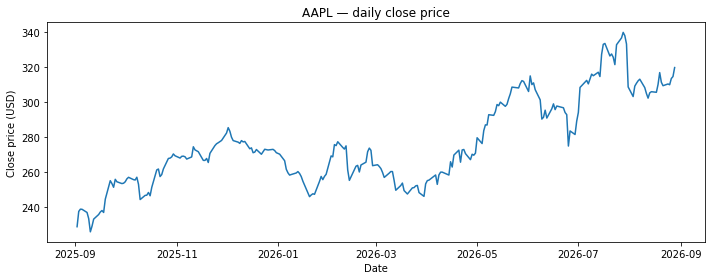

In [1]:
import matplotlib.pyplot as plt
import yfinance as yf

# Download daily prices (end date is exclusive, so we use 1 Sep 2026)
close = yf.Ticker("AAPL").history(start="2025-09-01", end="2026-08-31")["Close"]

plt.figure(figsize=(10, 4))
plt.plot(close)
plt.title("AAPL — daily close price")
plt.xlabel("Date")
plt.ylabel("Close price (USD)")
plt.tight_layout()
plt.show()


Compute the daily return and daily logarithmic return and create plots to illustrate the patterns of both returns.


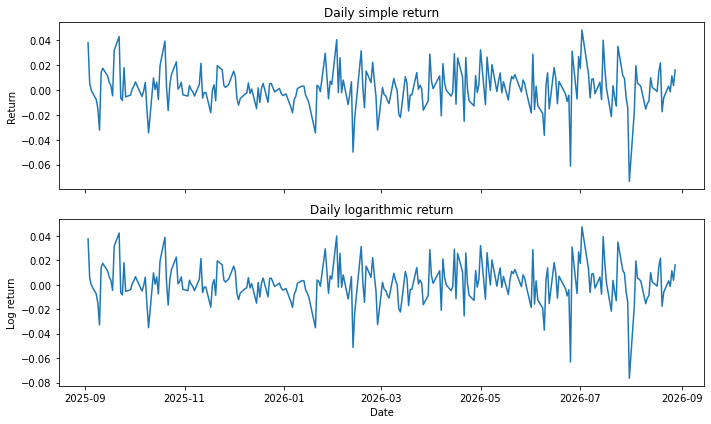

In [2]:
import numpy as np

# Simple daily return: (P_t - P_{t-1}) / P_{t-1}
daily_return = (close-close.shift(1))/close.shift(1)

# Log daily return: ln(P_t / P_{t-1})
log_return = np.log(close/close.shift(1))

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(daily_return)
axes[0].set_title("Daily simple return")
axes[0].set_ylabel("Return")

axes[1].plot(log_return)
axes[1].set_title("Daily logarithmic return")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Log return")

plt.tight_layout()
plt.show()


Explain under what circumstances these two types of returns can be considered approximately identical.

The two returns are related by $\hat r_i = \ln(1+r_i)$. A Taylor expansion around $r_i = 0$ gives
$$\hat r_i = r_i - \frac{r_i^2}{2} + \frac{r_i^3}{3} - \dots$$
so $\hat r_i \approx r_i$ whenever the relative price change $|r_i|$ is small, i.e. when the price changes little between two consecutive observations (short time steps, low volatility). The difference is of order $r_i^2/2$. For typical daily moves of about 1-2% this is only $10^{-4}$, which is why the two plots above are practically indistinguishable. Since $\ln(1+x) \le x$, the log return is always slightly smaller than the simple return, and the gap only becomes visible on days with large moves (e.g. the $\approx -7\%$ day at the end of July 2026). For longer horizons (monthly, yearly) or very volatile assets the approximation breaks down.

### b)
Plot the histogram of daily logarithmic returns, compute the sample mean ˆμ and variance
ˆσ2, and produce the quantile-quantile plot, i.e., daily logarithmic returns vs. normal
distribution N(ˆμ, ˆσ2).

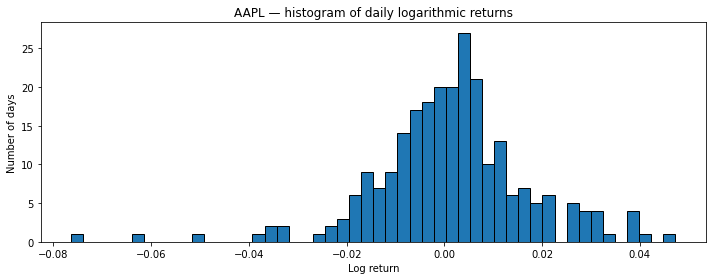

Sample mean: 0.0013422049182603858
Sample variance: 0.00025250232445903027


In [3]:
log_returns_clean=log_return.dropna()
plt.figure(figsize=(10, 4))
plt.hist(log_returns_clean, bins=50, edgecolor="black")
plt.title("AAPL — histogram of daily logarithmic returns")
plt.xlabel("Log return")
plt.ylabel("Number of days")
plt.tight_layout()
plt.show()


mean_lr=log_returns_clean.mean()
var_lr=log_returns_clean.var()
sd_lr=np.sqrt(var_lr)

print("Sample mean:", mean_lr)
print("Sample variance:", var_lr)



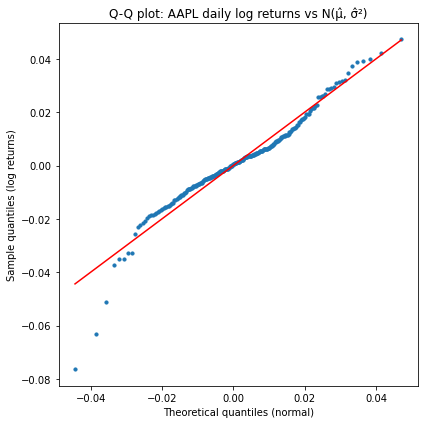

In [4]:
from scipy.stats import norm

# Empirical quantiles (sorted data) vs. normal quantiles at probabilities (k-0.5)/n
sample_q=np.sort(log_returns_clean)
n=len(sample_q)
probabilities=(np.arange(1,n+1)-0.5)/n
theory_q=norm.ppf(probabilities,loc=mean_lr,scale=sd_lr)

plt.figure(figsize=(6, 6))
plt.scatter(theory_q,sample_q,s=10)
plt.plot(theory_q,theory_q,color="red")
plt.title("Q-Q plot: AAPL daily log returns vs N(μ̂, σ̂²)")
plt.xlabel("Theoretical quantiles (normal)")
plt.ylabel("Sample quantiles (log returns)")
plt.tight_layout()
plt.show()

Repeat the above process for the weekly close prices (4 years - 2022,2023,2024,2025), and
compare the Q Q plot patterns of weekly and daily returns.

Daily  2022-2025: mean = 0.0004260373730286203 , variance = 0.00032051903834754325
Weekly 2022-2025: mean = 0.002295987301335746 , variance = 0.001477167758908476


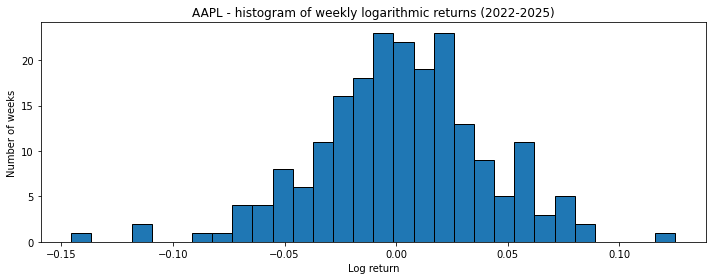

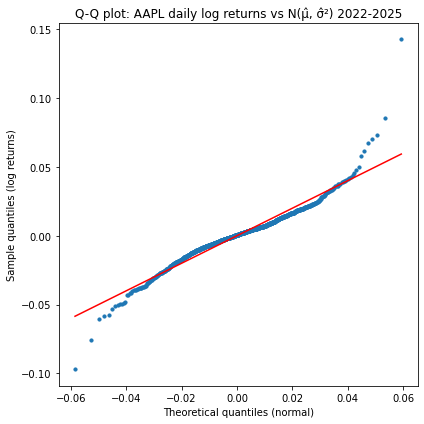

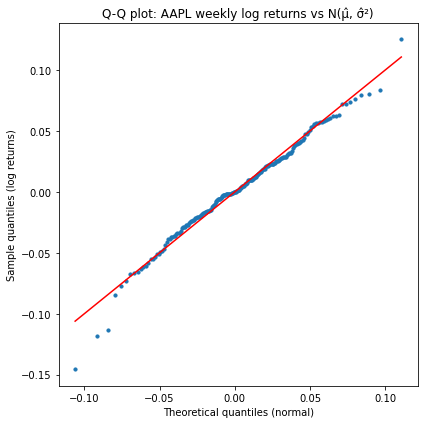

In [5]:
close_day = yf.Ticker("AAPL").history(start="2022-01-01", end="2025-12-31")["Close"]
close_week = yf.Ticker("AAPL").history(start="2022-01-01", end="2025-12-31", interval="1wk")["Close"]

day_log_returns=np.log(close_day/close_day.shift(1))
day_log_returns=day_log_returns.dropna()
mean_d=day_log_returns.mean()
var_d=day_log_returns.var()
sd_d=np.sqrt(var_d)

week_log_returns=np.log(close_week/close_week.shift(1))
week_log_returns=week_log_returns.dropna()
mean_w=week_log_returns.mean()
var_w=week_log_returns.var()
sd_w=np.sqrt(var_w)

print("Daily  2022-2025: mean =", mean_d, ", variance =", var_d)
print("Weekly 2022-2025: mean =", mean_w, ", variance =", var_w)

plt.figure(figsize=(10, 4))
plt.hist(week_log_returns, bins=30, edgecolor="black")
plt.title("AAPL - histogram of weekly logarithmic returns (2022-2025)")
plt.xlabel("Log return")
plt.ylabel("Number of weeks")
plt.tight_layout()
plt.show()

# Q-Q plot, daily returns 2022-2025
sample_q=np.sort(day_log_returns)
n=len(sample_q)
probabilities=(np.arange(1,n+1)-0.5)/n
theory_q=norm.ppf(probabilities,loc=mean_d,scale=sd_d)

plt.figure(figsize=(6, 6))
plt.scatter(theory_q,sample_q,s=10)
plt.plot(theory_q,theory_q,color="red")
plt.title("Q-Q plot: AAPL daily log returns vs N(μ̂, σ̂²) 2022-2025")
plt.xlabel("Theoretical quantiles (normal)")
plt.ylabel("Sample quantiles (log returns)")
plt.tight_layout()
plt.show()

# Q-Q plot, weekly returns 2022-2025
sample_q=np.sort(week_log_returns)
n=len(sample_q)
probabilities=(np.arange(1,n+1)-0.5)/n
theory_q=norm.ppf(probabilities,loc=mean_w,scale=sd_w)

plt.figure(figsize=(6, 6))
plt.scatter(theory_q,sample_q,s=10)
plt.plot(theory_q,theory_q,color="red")
plt.title("Q-Q plot: AAPL weekly log returns vs N(μ̂, σ̂²)")
plt.xlabel("Theoretical quantiles (normal)")
plt.ylabel("Sample quantiles (log returns)")
plt.tight_layout()
plt.show()

**Comparison.** The daily Q-Q plots have the typical S-shape of a heavy-tailed distribution: the points lie close to the line in the centre, but bend below it in the left tail and above it in the right tail. Extreme daily moves (up to -10% and +14% in 2022-2025) are much more frequent than a normal distribution predicts, and the centre of the distribution is more peaked. The weekly Q-Q plot follows the line much more closely and only deviates for a handful of extreme weeks. This is consistent with the central limit theorem: a weekly log return is the sum of about five daily log returns, so its distribution is closer to normal. The normal (log-normal price) model is therefore a better description at the weekly scale than at the daily scale. Note also that $\hat\mu_w \approx 5.4\,\hat\mu_d$ and $\hat\sigma_w^2 \approx 4.6\,\hat\sigma_d^2$, roughly as expected when weekly returns are sums of about five independent daily returns.

### 2
Monte Carlo

Compute the expected value of $1/\sqrt{U}$ for $U \sim \mathcal{U}(0, 1)$ using Monte Carlo method.

$$E\left[\frac{1}{\sqrt U}\right] = \int_0^1 u^{-1/2}\,du = \big[2\sqrt u\,\big]_0^1 = 2, \qquad E\left[\Big(\frac{1}{\sqrt U}\Big)^2\right] = \int_0^1 \frac{du}{u} = \infty .$$

So $Y = 1/\sqrt U$ has a finite mean but an **infinite variance**. The standard CLT, which gives errors of order $\sigma/\sqrt N$ and asymptotically normal errors, therefore does not apply directly.

In [6]:
rng=np.random.default_rng(seed=41)

n=1000

U=rng.uniform(0,1,n)
y=1/np.sqrt(U)

estimate=y.mean()
print("Monte Carlo estimate:", estimate)
print("Absolute error:", abs(estimate - 2))


Monte Carlo estimate: 2.010818219349918
Absolute error: 0.01081821934991778


Study the speed of convergence of MC method and whether the errors are asymptotically normal. Discuss your results.

To support your discussion produce figures with estimates and confidence intervals of these estimates for different number of samples $10^2, 10^3, 10^4, 10^5$. To test normality of errors show figures of the histogram together with the normal density with estimated parameters as well as Q-Q plot.

N=   100: estimate=1.9186, 95% CI=[1.5504, 2.2868]
N=  1000: estimate=1.9650, 95% CI=[1.7618, 2.1682]
N= 10000: estimate=2.0087, 95% CI=[1.9547, 2.0628]
N=100000: estimate=2.0364, 95% CI=[1.9363, 2.1366]


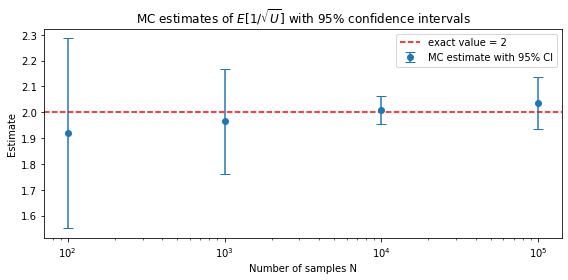

In [7]:
# One MC estimate and its 95% confidence interval for each sample size
Ns=[10**2,10**3,10**4,10**5]
estimates=[]
half_widths=[]

for n in Ns:
    y=1/np.sqrt(rng.uniform(0,1,n))
    est=y.mean()
    se=y.std(ddof=1)/np.sqrt(n)
    estimates.append(est)
    half_widths.append(1.96*se)
    print(f"N={n:>6}: estimate={est:.4f}, 95% CI=[{est-1.96*se:.4f}, {est+1.96*se:.4f}]")

plt.figure(figsize=(8, 4))
plt.errorbar(Ns,estimates,yerr=half_widths,fmt="o",capsize=5,label="MC estimate with 95% CI")
plt.axhline(2,color="red",linestyle="--",label="exact value = 2")
plt.xscale("log")
plt.title("MC estimates of $E[1/\sqrt{U}]$ with 95% confidence intervals")
plt.xlabel("Number of samples N")
plt.ylabel("Estimate")
plt.legend()
plt.tight_layout()
plt.show()

N=   100: mean |error|=0.18997, CI coverage=0.861
N=  1000: mean |error|=0.07448, CI coverage=0.894
N= 10000: mean |error|=0.02601, CI coverage=0.913


N=100000: mean |error|=0.00871, CI coverage=0.942


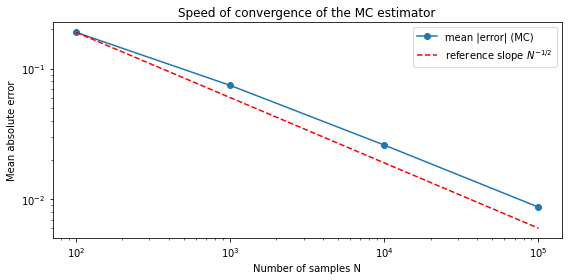

In [8]:
# Repeat the MC experiment M times for each N to study the distribution of the error
M=1000
errors={}
coverage={}

for n in Ns:
    err=np.empty(M)
    inside=0
    for m in range(M):
        y=1/np.sqrt(rng.uniform(0,1,n))
        est=y.mean()
        se=y.std(ddof=1)/np.sqrt(n)
        err[m]=est-2
        inside+=abs(est-2)<=1.96*se
    errors[n]=err
    coverage[n]=inside/M
    print(f"N={n:>6}: mean |error|={np.abs(err).mean():.5f}, CI coverage={coverage[n]:.3f}")

mean_abs_err=[np.abs(errors[n]).mean() for n in Ns]

plt.figure(figsize=(8, 4))
plt.loglog(Ns,mean_abs_err,"o-",label="mean |error| (MC)")
plt.loglog(Ns,mean_abs_err[0]*np.sqrt(Ns[0])/np.sqrt(Ns),"--",color="red",label="reference slope $N^{-1/2}$")
plt.title("Speed of convergence of the MC estimator")
plt.xlabel("Number of samples N")
plt.ylabel("Mean absolute error")
plt.legend()
plt.tight_layout()
plt.show()

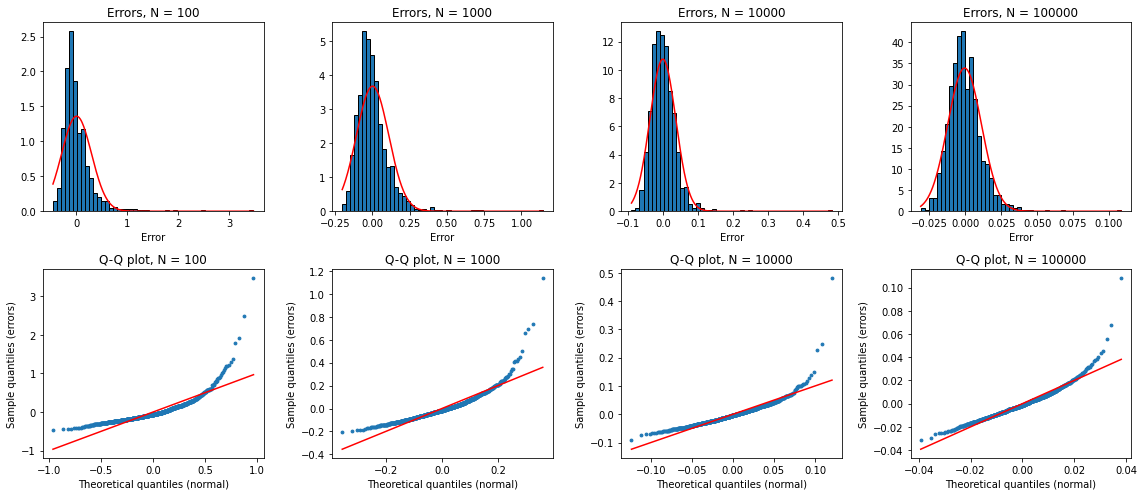

In [9]:
# Histogram of errors with fitted normal density (top) and Q-Q plot vs fitted normal (bottom)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for j, n in enumerate(Ns):
    err=errors[n]
    mu=err.mean()
    sd=err.std(ddof=1)

    x=np.linspace(err.min(),err.max(),400)
    axes[0, j].hist(err,bins=50,density=True,edgecolor="black")
    axes[0, j].plot(x,norm.pdf(x,loc=mu,scale=sd),color="red")
    axes[0, j].set_title(f"Errors, N = {n}")
    axes[0, j].set_xlabel("Error")

    sample_q=np.sort(err)
    probabilities=(np.arange(1,M+1)-0.5)/M
    theory_q=norm.ppf(probabilities,loc=mu,scale=sd)
    axes[1, j].scatter(theory_q,sample_q,s=8)
    axes[1, j].plot(theory_q,theory_q,color="red")
    axes[1, j].set_title(f"Q-Q plot, N = {n}")
    axes[1, j].set_xlabel("Theoretical quantiles (normal)")
    axes[1, j].set_ylabel("Sample quantiles (errors)")

plt.tight_layout()
plt.show()

**Speed of convergence.** The estimates get closer to 2 as $N$ grows and the confidence intervals become narrower. On the log-log plot the mean absolute error follows the reference slope $N^{-1/2}$ closely, but over each tenfold increase of $N$ it decreases by a factor of 2.6-3.0, slightly less than $\sqrt{10} \approx 3.16$. This is caused by the infinite variance. Since $P(Y > y) = P(U < y^{-2}) = y^{-2}$, $Y$ lies exactly on the border of the domain of attraction of the normal law. The generalised CLT then gives an error of order $\sqrt{\ln N / N}$ instead of $1/\sqrt N$, i.e. convergence that is only slightly slower than usual.

**Normality of the errors.** Because the variance is infinite, the classical CLT does not apply directly. The histograms are clearly right-skewed with a long right tail: rare samples with very small $U$ produce huge values of $1/\sqrt U$ and pull the estimate up. The fitted normal density does not match the shape of the histogram. In the Q-Q plots the points bend away from the line in the right tail. This departure is strongest for $N = 10^2$ and becomes milder as $N$ grows. The errors do become asymptotically normal, but only very slowly (with the logarithmic correction above).

**Confidence intervals.** Because the errors are not normal and the sample standard deviation $s$ underestimates the true spread (the true variance is infinite), the intervals $\hat\mu \pm 1.96\,s/\sqrt N$ contain the true value less often than 95% of the time: from 86% for $N = 10^2$ up to 94% for $N = 10^5$. These intervals should therefore be read with caution for this integrand. The infinite variance also makes $s$ unstable: one very small $U$ can inflate it, so a larger $N$ does not always give a narrower interval in a single run. This is visible in our run: the interval for $N = 10^5$ is wider than the one for $N = 10^4$.

### 3
Simulation of stock price paths.
a. We have the discrete price model S(ti+1) = S(ti)(1+μδt+σ
√
δtZ), where Z ∼ N(0, 1), T = 1,
S0 = 170, σ = 0.344, and μ = 0.1.
 Choose the number of time intervals L = 5 and plot the price evolution of St for t = i ·Δt
with i = 0, . . . ,L and Δt = T
L.
 Repeat the simulation M = 5000 times, and store the simulated ST to make the histogram.
 Repeat the simulation (above steps) for increasing L = 10, 20, 50, 100 to see how the his-
togram of ST changes, compared with the theoretical distribution given by the continuous-
time stock price model, i.e., ST = S0e(μ−1
2σ2)T+σ
√
TZ. Show the results obtained for dif-
ferent values of L in the form of empirical distribution functions plotted on one gure
together the theoretical distribution function.

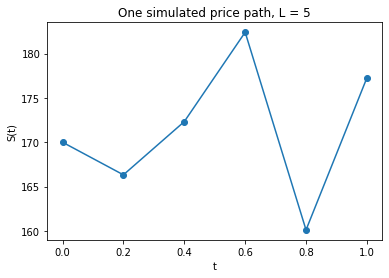

In [10]:
np.random.seed(41)

S0, sigma, mu, T = 170, 0.344, 0.1, 1

L=5
dt=T/L

S=[S0]

# S(t_{i+1}) = S(t_i) * (1 + mu*dt + sigma*sqrt(dt)*Z)
for i in range(L):
    z=np.random.randn()
    S_next=S[-1]*(1+mu*dt+sigma*np.sqrt(dt)*z)
    S.append(S_next)

t=np.arange(L+1)*dt
plt.plot(t, S, marker='o')
plt.xlabel('t'); plt.ylabel('S(t)')
plt.title('One simulated price path, L = 5')
plt.show()

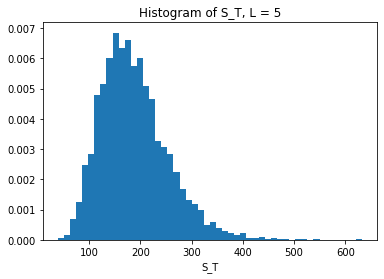

In [11]:
# Simulate M paths at once (vectorised over paths) and return S_T
def simulate_ST(L,M=5000):
    dt=T/L
    S=np.full(M,S0,dtype=float)
    for i in range(L):
        z=np.random.randn(M)
        S=S*(1+mu*dt+sigma*np.sqrt(dt)*z)
    return S

ST=simulate_ST(5) 
plt.hist(ST, bins=50, density=True)
plt.xlabel('S_T'); plt.title('Histogram of S_T, L = 5')
plt.show()

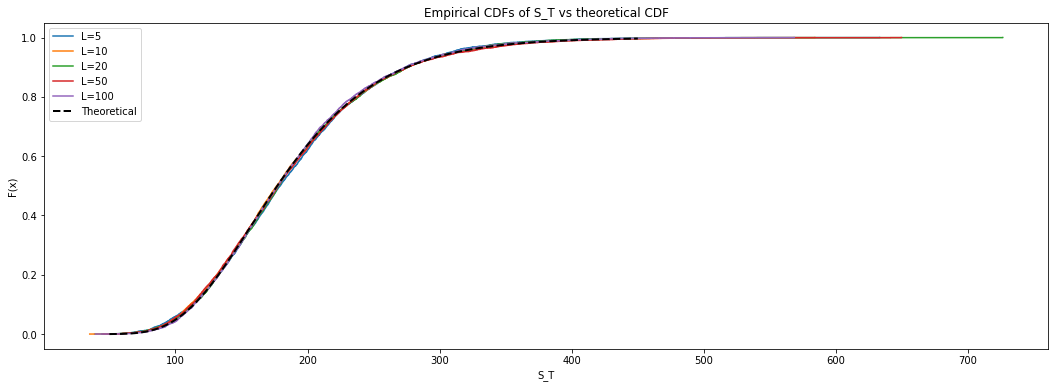

In [12]:
plt.figure(figsize=(18, 6))


np.random.seed(41)

LS=[5,10,20,50,100]

for L in LS:
    ST=np.sort(simulate_ST(L))
    edcf=np.arange(1,len(ST)+1)/len(ST)
    plt.step(ST,edcf,where='post',label=f'L={L}')

# Theoretical CDF: ln(S_T/S0) ~ N((mu - sigma^2/2) T, sigma^2 T)
x=np.linspace(50,450,500)
F=norm.cdf((np.log(x/S0)-(mu-0.5*sigma**2)*T)/(sigma*np.sqrt(T)))
plt.plot(x, F, 'k--', linewidth=2, label='Theoretical')
plt.xlabel('S_T'); plt.ylabel('F(x)')
plt.title('Empirical CDFs of S_T vs theoretical CDF')
plt.legend(); plt.show()

All empirical distribution functions lie very close to the theoretical one. As $L$ increases, the discrete model converges to the continuous geometric Brownian motion, and the empirical CDFs approach the log-normal CDF. Already for $L = 5$ the difference is small, because the drift and volatility over one year are moderate. With $L = 5$ the product of only five factors $(1 + \mu\Delta t + \sigma\sqrt{\Delta t}Z_i)$ is less right-skewed than the log-normal, and a factor can even become negative for large negative $Z_i$. These effects disappear as $L$ grows. The remaining small wiggles of the curves are Monte Carlo noise from the finite $M$.

Using the continuous-time stock price model as in a) and M = 102, 103, 104, 105 simulations,
estimate the expectation of ST with standard Monte Carlo simulation and with the antithetic
variables technique. Compute the 95% confidence intervals of your estimates and the ratio
their widths IM/IAM

In [13]:
S0, sigma, mu, T = 170, 0.344, 0.1, 1
exact=S0*np.exp(mu*T)
rng=np.random.default_rng(seed=41)

ms=[10**2,10**3,10**4,10**5]

# Exact solution of the continuous-time model for given Z
def ST_exact(z):
    return S0*np.exp((mu-0.5*sigma**2)*T+sigma*np.sqrt(T)*z)

print(f"E[S_T]={exact:.4f}")

for m in ms:
    # standard MC with m samples
    z=rng.standard_normal(m)
    y=ST_exact(z)
    est=y.mean()
    hw=1.96*y.std(ddof=1)/np.sqrt(m)

    # antithetic: m/2 pairs (Z, -Z), i.e. the same number m of evaluations
    z2=z[:m//2]
    y2=0.5*(ST_exact(z2)+ST_exact(-z2))
    est2=y2.mean()
    hw2=1.96*y2.std(ddof=1)/np.sqrt(m//2)

    print(f"M={m:>6}: MC = {est:.3f}, CI=[{est-hw:.3f}, {est+hw:.3f}] | "
          f"AMC = {est2:.3f}, CI=[{est2-hw2:.3f}, {est2+hw2:.3f}] | "
          f"I_M/I_AM = {hw/hw2:.3f}")

E[S_T]=187.8791
M=   100: MC = 181.234, CI=[169.748, 192.719] | AMC = 186.090, CI=[183.155, 189.025] | I_M/I_AM = 3.913
M=  1000: MC = 188.182, CI=[183.980, 192.384] | AMC = 188.386, CI=[186.961, 189.811] | I_M/I_AM = 2.949
M= 10000: MC = 187.746, CI=[186.439, 189.052] | AMC = 187.520, CI=[187.103, 187.938] | I_M/I_AM = 3.127
M=100000: MC = 187.667, CI=[187.252, 188.081] | AMC = 187.889, CI=[187.751, 188.027] | I_M/I_AM = 3.005


Both methods converge to $E[S_T] = S_0e^{\mu T} = 187.879$ and every confidence interval contains the true value. For the same $M$ the antithetic interval is about 3 times narrower. This agrees with theory. With $m = E[S_T]$,
$$\operatorname{Var}(S_T) = m^2\big(e^{\sigma^2 T} - 1\big), \qquad \operatorname{Cov}\big(S_T(Z), S_T(-Z)\big) = m^2\big(e^{-\sigma^2 T} - 1\big) < 0,$$
so the ratio of the interval widths at equal cost is
$$\frac{I_M}{I_{AM}} = \sqrt{\frac{\operatorname{Var}(S_T)}{\operatorname{Var}(S_T) + \operatorname{Cov}(S_T(Z),S_T(-Z))}} = \sqrt{\frac{e^{\sigma^2 T} - 1}{e^{\sigma^2 T} + e^{-\sigma^2 T} - 2}} \approx 2.99 .$$
The simulated ratios (3.91, 2.95, 3.13, 3.01) scatter around this value. The scatter is largest for $M = 10^2$, where the sample standard deviations themselves are noisy. The method works well here because $S_T$ is a monotone, nearly linear function of $Z$ for moderate $\sigma$, which makes $S_T(Z)$ and $S_T(-Z)$ strongly negatively correlated. Reducing the interval width by a factor of 3 is equivalent to using about 9 times more samples with standard Monte Carlo.

### 4
Historical volatility

a. Use the same data as in 1) and compute estimates of historical volatility for the daily and
weekly Apple data.


In [14]:
sigma_d=day_log_returns.std()
sigma_w=week_log_returns.std()

# Annualise: sigma = s / sqrt(dt), dt = 1/252 (daily) or 1/52 (weekly)
sigma_d_anum=sigma_d*np.sqrt(252)
sigma_w_anum=sigma_w*np.sqrt(52)

print(f"Daily:  sigma per day  = {sigma_d:.5f}, annualised = {sigma_d_anum:.4f}")
print(f"Weekly: sigma per week = {sigma_w:.5f}, annualised = {sigma_w_anum:.4f}")

Daily:  sigma per day  = 0.01790, annualised = 0.2842
Weekly: sigma per week = 0.03843, annualised = 0.2772


b. Produce figures of daily and weekly volatility estimates using exponentially weighted moving
average method (Similar to Figure 20.1 in the book). Use 20 first observations to get initial σ∗
and w = 0.94.

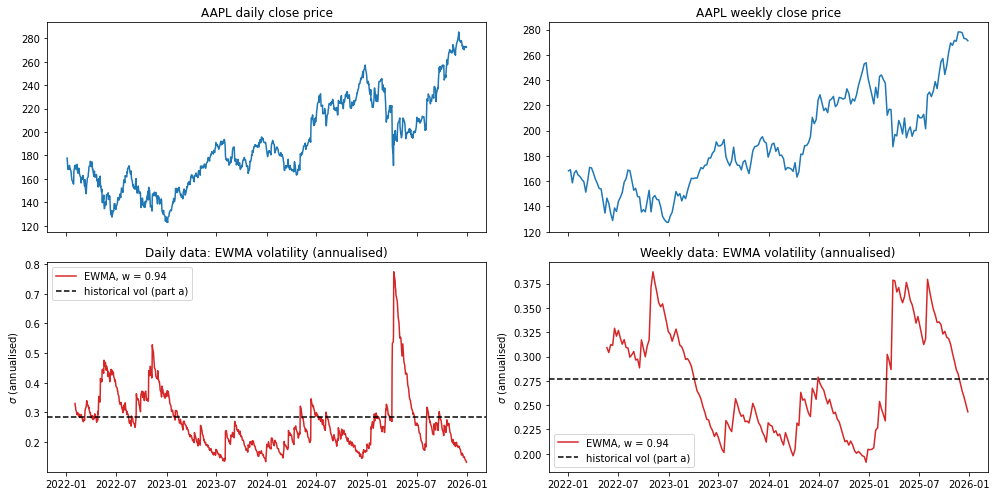

In [15]:
import pandas as pd

# sigma_n^2 = w * sigma_{n-1}^2 + (1-w) * u_n^2, started from the sample variance of the first n_init returns
def ewma(returns, w=0.94, n_init=20):
    u=returns.values
    var=np.full(len(u),np.nan)
    var[n_init-1]=np.var(u[:n_init],ddof=1)
    for i in range(n_init,len(u)):
        var[i]=w*var[i-1]+(1-w)*u[i]**2
    return pd.Series(np.sqrt(var),index=returns.index)

vol_d = ewma(day_log_returns)  * np.sqrt(252)   # annualised daily-data estimate
vol_w = ewma(week_log_returns) * np.sqrt(52)    # annualised weekly-data estimate
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex="col")    


axes[0, 0].plot(close_day)
axes[0, 0].set_title("AAPL daily close price")
axes[1, 0].plot(vol_d, color="tab:red", label="EWMA, w = 0.94")
axes[1, 0].axhline(day_log_returns.std() * np.sqrt(252), color="k", ls="--",
                   label="historical vol (part a)")
axes[1, 0].set_title("Daily data: EWMA volatility (annualised)")
axes[1, 0].legend()
axes[0, 1].plot(close_week)
axes[0, 1].set_title("AAPL weekly close price")
axes[1, 1].plot(vol_w, color="tab:red", label="EWMA, w = 0.94")
axes[1, 1].axhline(week_log_returns.std() * np.sqrt(52), color="k", ls="--",
                   label="historical vol (part a)")
axes[1, 1].set_title("Weekly data: EWMA volatility (annualised)")
axes[1, 1].legend()
for ax in axes[1]:
    ax.set_ylabel(r"$\sigma$ (annualised)")
plt.tight_layout()
plt.show()

The volatility rises sharply after large price movements and then decays back towards the historical estimate of part a). The most striking example is April 2025, when the daily EWMA volatility jumps from about 25% to almost 80%. The weekly curve is smoother and slower to react to price spikes: with $w = 0.94$ the effective memory is about $1/(1-w) \approx 17$ observations, i.e. about 3.5 weeks for daily data but about 4 months for weekly data. The first 20 observations are only used to compute $\sigma^*$, so each curve starts at the 20th return. The starting value matters less and less, because its weight shrinks as $w^k$.

c. In view of results obtained in b) do you think that the asset pricing model presented during the third lecture is appropriate for this data.

The model from the lecture (geometric Brownian motion) assumes a **constant** volatility $\sigma$. The figure above clearly contradicts this. The EWMA estimate varies between roughly 13% and 77% for daily data and between 19% and 39% for weekly data, and it shows volatility clustering: calm periods (most of 2023-2024) alternate with turbulent periods (2022, April 2025). The heavy tails in the daily Q-Q plots of question 1b point in the same direction, since a mixture of normal distributions with different variances is heavy-tailed. The constant-volatility model is therefore not fully appropriate for this data, especially at the daily scale and during market stress. It can still serve as a reasonable first approximation over longer horizons, where the weekly returns are close to normal and the average volatility is stable (part a). Models with time-varying volatility (e.g. GARCH or stochastic volatility) would describe the data better.

### 5
Binomial method: fixed strike lookback put (a) and shout put (b), with S0 = 1, T = 3, r = 0.05, sigma = 0.3, E = 1.5, M = 12.

In [16]:
import numpy as np
from itertools import product
from math import comb

S0, T, r, sigma, E, M = 1.0, 3.0, 0.05, 0.3, 1.5, 12
dt = T/M

# Binomial parameters (Higham): d = 1/u, risk-neutral probability p
beta = 0.5*(np.exp(-r*dt) + np.exp((r + sigma**2)*dt))
u = beta + np.sqrt(beta**2 - 1)
d = 1/u
p = (np.exp(r*dt) - d)/(u - d)
print(f"u = {u:.6f}, d = {d:.6f}, p = {p:.6f}")

# a) Fixed strike lookback put: enumerate all 2^M paths and track S_min
price_lb = 0.0
for path in product([0, 1], repeat=M):          # 1 = up move, 0 = down move
    k = np.cumsum(path)                         # number of ups after each step
    S = S0*u**k*d**(np.arange(1, M+1) - k)
    S_min = min(S0, S.min())
    price_lb += p**k[-1]*(1 - p)**(M - k[-1])*max(E - S_min, 0)
price_lb *= np.exp(-r*T)
print(f"a) Lookback put price = {price_lb:.6f}")

# b) Shout put. Shouting at a node with price S at time t_n locks in E-S, so the remaining payoff is
#    (E-S) + max(S - S_T, 0): discounted (E-S) plus an at-the-money European put with strike S.
#    Since d = 1/u the tree is scale invariant, so that put equals S * put_atm[m] (m = steps left).
def put_atm(m):
    j = np.arange(m + 1)
    payoff = np.maximum(1 - u**j*d**(m - j), 0)
    probs = np.array([comb(m, i) for i in j])*p**j*(1 - p)**(m - j)
    return np.exp(-r*m*dt)*np.sum(probs*payoff)

S_T = S0*u**np.arange(M + 1)*d**(M - np.arange(M + 1))
V = np.maximum(E - S_T, 0)                       # no shout: European put payoff
for n in range(M - 1, -1, -1):                   # shouting allowed for 0 <= t_n < T
    S = S0*u**np.arange(n + 1)*d**(n - np.arange(n + 1))
    cont = np.exp(-r*dt)*(p*V[1:] + (1 - p)*V[:-1])
    shout = np.exp(-r*(M - n)*dt)*(E - S) + S*put_atm(M - n)
    V = np.where(S < E, np.maximum(cont, shout), cont)
print(f"b) Shout put price = {V[0]:.6f}")

# Reference: European put with the same parameters
j = np.arange(M + 1)
probs = np.array([comb(M, i) for i in j])*p**j*(1 - p)**(M - j)
print(f"   European put price = {np.exp(-r*T)*np.sum(probs*np.maximum(E - S_T, 0)):.6f}")


u = 1.164347, d = 0.858850, p = 0.503207
a) Lookback put price = 0.655177
b) Shout put price = 0.557571
   European put price = 0.411506


**Binomial tree.** $\beta = \frac12\big(e^{-r\delta t} + e^{(r+\sigma^2)\delta t}\big)$, $u = \beta + \sqrt{\beta^2-1}$, $d = 1/u$, $p = (e^{r\delta t}-d)/(u-d)$, and node prices $S_i^n = S_0u^id^{n-i}$.

**a)** The payoff depends on the path minimum, so with $M = 12$ we enumerate all $2^{12} = 4096$ paths: $V_0 = e^{-rT}\sum_{\text{paths}} p^k(1-p)^{M-k}\max(E - S_{\min}, 0) = \mathbf{0.6552}$.

**b)** Shouting at price $S < E$ turns the payoff into $(E - S) + \max(S - S_T, 0)$: the discounted amount $E - S$ plus an at-the-money put with strike $S$, worth $S\cdot P_{\text{atm}}(M-n)$ because the tree is scale invariant ($d = 1/u$). Stepping backwards from $V_i^M = \max(E - S_i^M, 0)$, at every node with $S_i^n < E$ the holder takes the larger of the continuation value and the shout value. This gives $V_0 = \mathbf{0.5576}$.

For comparison, the European put costs 0.4115. As expected, European put < shout put < lookback put: the shout lets the holder lock in one favourable price, while the lookback automatically locks in the most favourable one.